In [12]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import make_regression
from sklearn.model_selection import train_test_split
%matplotlib inline

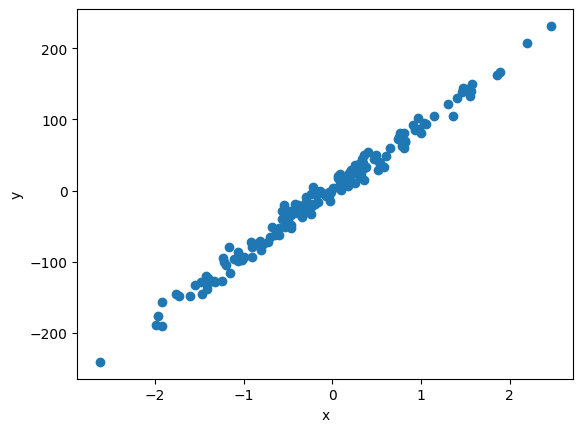

In [13]:
x, y = make_regression(n_samples=150, n_features=1, noise=10, random_state=42)
y = y.reshape(-1, 1)
plt.plot(x, y, 'o')
plt.xlabel('x')
plt.ylabel('y')
plt.show()

In [14]:
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.2, random_state=42)
X_train = np.hstack((x_train, np.ones(x_train.shape)))
X_test = np.hstack((x_test, np.ones(x_test.shape)))
print(X_train.shape, X_test.shape, y_train.shape, y_test.shape)

(120, 2) (30, 2) (120, 1) (30, 1)


In [15]:
np.random.seed(0)
theta = np.random.randn(2, 1)
print(theta)

[[1.76405235]
 [0.40015721]]


In [16]:
def model(X, theta):
    return X.dot(theta)

In [17]:
def gradient_descent(X, y, theta, learning_rate, n_iterations):
    cost_history = np.zeros(n_iterations)
    for i in range(n_iterations):
        theta = theta - learning_rate * grad(X, y, theta)
        cost_history[i] = cost_function(X, y, theta)
    return theta, cost_history

In [18]:
def grad(X, y, theta):
    m = len(y)
    return 1/m * X.T.dot(model(X, theta) - y)

In [19]:
def cost_function(X, y, theta):
    m = len(y)
    return 1/(2*m) * np.sum((model(X, theta) - y)**2)

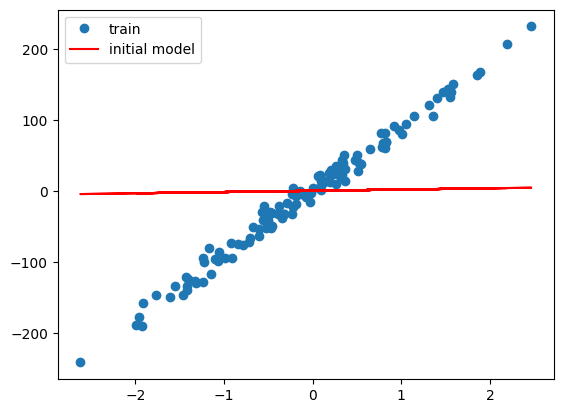

In [20]:
plt.plot(x_train, y_train, 'o', label='train')
plt.plot(x_train, model(X_train, theta), c='r', label='initial model')
plt.legend()
plt.show()

In [21]:
n_iterations = 1000
learning_rate = 0.01
theta_final, cost_history = gradient_descent(X_train, y_train, theta, learning_rate, n_iterations)
print(theta_final)

[[90.32693066]
 [ 1.37599019]]


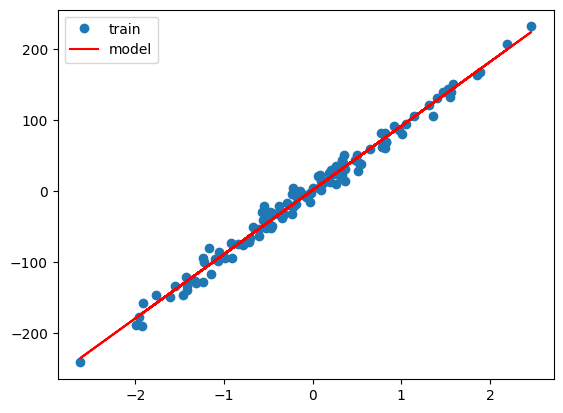

In [22]:
plt.plot(x_train, y_train, 'o', label='train')
plt.plot(x_train, model(X_train, theta_final), c='r', label='model')
plt.legend()
plt.show()

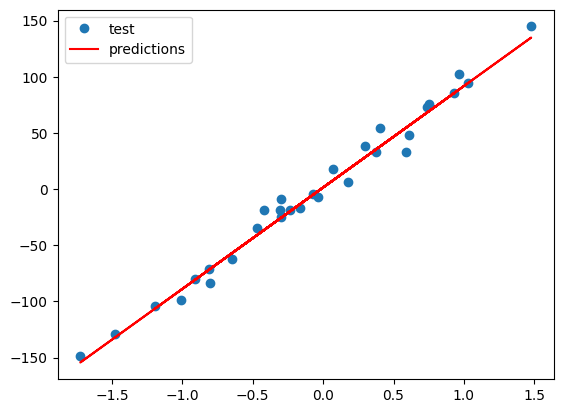

In [23]:
predictions = model(X_test, theta_final)
plt.plot(x_test, y_test, 'o', label='test')
plt.plot(x_test, predictions, c='r', label='predictions')
plt.legend()
plt.show()

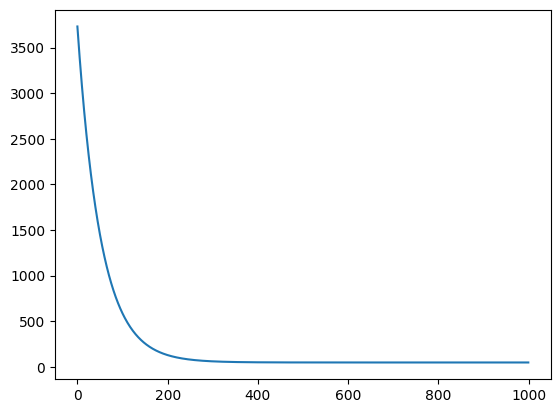

In [24]:
plt.plot(range(n_iterations), cost_history)
plt.show()

In [25]:
def coef_determination(y, pred):
    u = ((y - pred)**2).sum()
    v = ((y - y.mean())**2).sum()
    return 1 - u/v

coef_determination(y_test, predictions)

np.float64(0.983309974753688)